# 43 — Question 4: the filers

Which kinds of firm, institute and inventor patent eVTOL aircraft, and which designs and filing strategies do firms of different maturity follow?

Sub-questions 4.1 and 4.2 of the Labelling Analysis (2026-09-30). Every path comes from `labelling_analysis.yaml`; equations come from `lib/`, figures and tables from `viz/`.

This notebook reproduces every figure, table and number of chapter 4 of the 45-page document, and compares them with it (`viz.checks`). Chapter 4 reads the twelve classes of the wizard (`topType`: the seven classes of 20 aircraft or more of Figure 17, the five of Figures 19 and 20), never the five-class fold, so the class fold of 2026-10-01 (Stopped/Slowed Rotor Wing into Lift + Cruise) moves no number here. The differences from the document's tables are only the display names of 2026-09-28 (Tilt Rotor is printed Tilt Propulsor), which `viz.checks` maps. The method is reproduced as the document has it: nothing is changed (METHOD_NOTES.md item 4: the firms of Figure 17 are ranked on `firm` and dropped on `company_canonical`; here the two columns are equal, so the difference does not arise).

Figure 3 of 4.1's funding test is printed in chapter 1 (notebook 40); this notebook reproduces its lead from first patent to first flight for the nine funded firms. Outputs are written to `<output>/q4_filers/` (figures: pdf, png, csv, json; tables: csv, json). Regenerate this notebook with `python3 notebooks/_build/build_43.py`.

### Chapter 4 — The filers: which kinds of firm, institute and inventor patent eVTOL aircraft, and which designs and filing strategies do firms of different maturity follow?

Chapters 2 and 3 read the designs; this chapter reads the filers behind them, in two steps.

- **4.1: who files, and how concentrated filing is.** The filers are sorted by type and ranked by the aircraft they hold; each architecture class is asked whether one filer holds enough of it to decide its share; and the firms the AAM Reality Index rates are read against the one thing the index holds and the patents do not: the money they have raised.
- **4.2: who reshapes the design space.** The classes of the aircraft filed by firms filing for the first time are set against those of firms that filed before, and each firm's next aircraft is followed to the class it lands in.

## 0. Setup: paths and the analysis unit

The table lists every input this notebook can read, whether it exists and when it last changed. The load raises if a required input is missing.

In [1]:
import sys, pathlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
pd.set_option('display.max_colwidth', 120)
from viz import config, data
cfg = config.load()
config.show(cfg)[['group', 'key', 'exists', 'modified', 'size', 'path']]

,group,key,exists,modified,size,path
0,root,labelled,True,2026-09-25 14:05,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED
1,root,evtolnews,True,2026-09-22 15:12,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS
2,root,reference,True,2026-09-30 18:42,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
3,root,output,True,2026-10-01 19:52,dir,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analys...
4,labelled_dataset,aircraft_labels,True,2026-10-01 16:38,"2,211 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
5,labelled_dataset,figure_labels,True,2026-10-01 16:38,"2,953 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
6,labelled_dataset,label_dictionary,True,2026-10-01 16:38,46 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/output...
7,other_inputs,patent_facts,True,2026-10-01 16:37,"1,595 KB",/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
8,other_inputs,trl_per_aircraft,True,2026-09-22 14:41,224 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/0_labelling/inputs...
9,other_inputs,evtolnews_aircraft,True,2026-09-17 19:41,991 KB,/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/EVTOLNEWS_DS/0_source/aircraft.csv


The analysis unit is the representative primary aircraft: wizard-approved, passes the domain gate (no UAV/not-electric/STOL-only tag), one row per aircraft. Counts below must match the document.

In [2]:
ds = data.load_dataset(cfg)
pd.Series(ds.counts, name='count').to_frame()

,count
patents_acquired,1639
patents_wizard_approved,1109
patents_approved,879
patents_gated_out,230
variants_gated_out,257
primary_variants_gated_out,171
patents_analysis,543
approved_variants,963
primary_approved_variants,627
approved_figures,1538


### Tools used below

`frames.base` is the per-aircraft analysis frame (627 rows); `frames.filer_from_assignee` and `frames.firm_from_assignee` are the text rules that give a filer its type and a firm its name; `lib.concentration` holds the equations of 4.1 (coverage bands, effective number of filers, firm leverage), `lib.association` the tests (chi-square, Fisher, Spearman); `viz.checks` compares with the document. `verify` runs one table check and keeps its summary for the final overview; `numbers_check` does the same for the quoted numbers. A cell written in the thesis names (Tilt Propulsor) is compared with the document's wording through `checks.rename_map`.

In [3]:
import inspect
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from viz import frames, style, plots, save, checks
from lib import concentration, association

style.apply(cfg)
import thesis_style as ts; ts.use()                        # thesis base style, after the viz style
v = frames.base(ds, cfg)                                   # one row per unique aircraft (627)
WIN_NAMES = list(cfg.analysis['windows'])
COMPLETE = [w for w in WIN_NAMES if 'partial' not in w]    # the four windows with a complete priority year
W, _ = style.size(cfg, 'full')
pct = lambda x: f"{x:.0%}".replace('%', ' %')              # 0.53 -> '53 %'
pct1 = lambda x: f"{100 * x:.1f} %"                        # 0.0143 -> '1.4 %'
thin = lambda n: f"{int(n):,}".replace(',', ' ')           # 1 229
pval = lambda p: '< 0.001' if p < 0.001 else f"{p:.3f}" if p < 0.05 else f"{p:.2f}"   # the form of the document's p
WSHORT = {'<= 2011': '≤2011', '2012-15': '12–15', '2016-19': '16–19', '2020-23': '20–23', '2024-26 (partial)': '24–26*'}
CLASS_NAMES = {c: style.cls(c).name for c in style.CLASS_ORDER}
CHECKS, NUMBERS = [], []                                   # summaries kept for the overview at the end

def verify(frame, ref, name=None, doc_wording=True, **kw):
    if doc_wording and 'rename' not in kw:
        kw['rename'] = checks.rename_map(frame)
    r = checks.table(frame, ref, cfg, name=name, **kw)
    CHECKS.append(r)
    display(r.T.rename(columns={0: name or ref}))
    d = checks.detail(r)
    if len(d):
        display(d)

def numbers_check(values, expected=None):
    r = checks.numbers(values, '4', expected)
    NUMBERS.append(r)
    display(r)

def thesis_names(frame):
    '''A table as the thesis prints it: Tilt Rotor is Tilt Propulsor (the display rename of 2026-09-28).'''
    return frame.rename(columns=lambda c: str(c).replace('Tilt Rotor', 'Tilt Propulsor')).replace({'Tilt Rotor': 'Tilt Propulsor'})

## 4.1 — Which kinds of assignees file, and does any single firm hold enough of a class to decide its share?

#### Method

**Who a filer is.** Every patent names its owners, the assignees; the first one named is the **filer**. Its type is assigned by fixed text rules written for this thesis, applied to that name as the PatSeer export prints it; no language model and no sentence embedding is involved:


| filer type | recognised by | example |
|---|---|---|
| **Named company** | a legal form (Inc, GmbH, Ltd, 株式会社, 公司 …), an activity word (aviation, technology, systems …), a digit, a single brand word, or more than five words | Bell Textron Inc |
| **University / institute** | a university, institute, academy, college, polytechnic or public research centre | Beihang University |
| **Individual inventor** | a personal name: two to five words, or one name in Chinese, Japanese or Korean script | a private inventor filing in his or her own name |

A fourth type, *no assignee named*, is empty in this corpus. Companies, universities and institutes are the **named organisations**, called *firms* below; the spellings of one firm are merged into one name (Airbus Urban Mobility into Airbus) by a hand-written name table, with fuzzy string matching for spellings the table lacks. An individual inventor cannot be followed reliably from patent to patent, since one name can be transliterated two ways, so where filers are counted each individual's patent is its own filer, and wherever a firm is followed over time the individuals are left out.

Three measurements answer this question.

- **Who files and how much each holds: Figure 16.**
  - *(i)* The named organisations ranked by their unique aircraft, largest first, and the cumulative share of the 627 aircraft they hold, cut where firms hold 10 or more, 5-9, 2-4 and 1 aircraft each; the firms the AAM Reality Index has rated are marked.
  - *(ii)* The share of each filer type, over all years counted twice, in patents and in unique aircraft, then per priority window, in aircraft. The patents are the 879 **representative patents**: every patent kept for the analysis, counted once, including those that only draw an aircraft already counted on another patent. The two all-years bars show whether the unit changes the answer.
  - *(iii)* The named organisations filing in each window, split into **first-time filers**, firms whose earliest eVTOL aircraft in the corpus falls in that window (the number inside the dark bar), and **firms filing again**, which filed in an earlier window (the "+N again" above the bar): 57 first-time and 7 again in 2016-19, 82 and 19 in 2020-23.
  - *Unit:* the unique aircraft in (i) and (ii), because a design filed five times is one design; the organisation in (iii), because a first filing is an event of the firm.
- **Whether one filer holds enough of a class to decide its share: Figure 17.** Read on the 7 classes with 20 aircraft or more; in a smaller class one filer's aircraft move the share by large steps.
  - *(i)* Per class: the share of its aircraft held by its largest filer over all years (bar), and the highest share one filer reaches within a single priority window such as 2016-19 (diamond; only windows with 10 or more of the class's aircraft, the partial 2024-26 window left out). On the tick: the class's filers and its effective number of filers.
  - **Effective number of filers = 1 / Σ sᵢ²**, where sᵢ is filer i's share of the class's aircraft: the ²D of the diversity box in chapter 2, computed over filers instead of archetypes. It says how many *equally sized* filers would give the same concentration. *Example, invented numbers:* a class of 10 aircraft, 5 from one firm and 1 each from five others, has Σ sᵢ² = 0.5² + 5 × 0.1² = 0.30 and so behaves as if split between 3.3 equal filers, although it has 6. When every filer holds one aircraft the number equals the filer count; when one filer holds everything it is 1.
  - *(ii)* **The weight of a single firm: removing one firm at a time.** For each firm with three aircraft or more, its aircraft are removed, every class's share of the remaining aircraft is recomputed, and the largest change is kept, in percentage points: over all years (bar) and within a single window of 30 aircraft or more (diamond). The eight firms that move a share most are drawn.
  - *Unit:* the unique aircraft; a firm that files one design several times moves nothing.
- **What the AAM Reality Index adds about the firms it rates: Figure 18.** The index (1.1) rates 18 firms that file here; they hold 147 of the aircraft (23 %). Chapter 1 has already tested whether their aircraft stand for the corpus (Table 5): they do not, since they differ from the rest in region, priority window, filer type and propulsor units, so what follows describes these firms, not the labelled dataset.
  - *What the index holds that the patents do not:* a disclosed funding amount, in US$ million, for 9 of the firms (May 2026 release); 4 are marked *corporate backed* with no amount, and 5 appear only in earlier releases, without funding. The index holds **no headcount and no market capitalisation**, so neither is read.
  - *What is tested:* on the 9 firms with an amount, funding against (i) their unique aircraft in the corpus and (ii) the lead from first patent to first flight of Figure 3, on the 8 firms whose first flight has happened; the priority year of their first patent is tested the same way and reported in the text, not drawn. Each is a **Spearman ρ**, whether one quantity rises as the other does, reading only the order of the values, with its p, as set out in the statistics box at the head of chapter 1.
  - *Unit:* the firm, because funding belongs to the firm. On 9 firms only a strong relation can be detected; a lead below zero only means that the firm's earliest filing is not in this corpus. Sources: AAM Reality Index (May 2026), PatSeer, human labelling.

### Who a filer is

`frames.filer_from_assignee` reads a filer's type from the first assignee as PatSeer prints it (the fixed text rules of the Method; no model); `frames.firm_from_assignee` and the grouper's table give the firm's name, with ten spellings folded by hand (`frames.FIRM_ALIASES`). `frames.filer_mix` counts the types in primary patents and in unique aircraft; `frames.filer_mix_representative` counts the 879 representative patents. Both are checked against the document. The fourth type, *no assignee named*, is empty.

In [4]:
assert int(v['filer'].eq(frames.NO_ASSIGNEE).sum()) == 0          # 'no assignee named' is empty in this corpus
fm = frames.filer_mix(v)
fmr = frames.filer_mix_representative(ds)
verify(fm, 'la_filer_mix', key=['filer'])
verify(fmr, 'la_filer_mix_rep', key=['filer'])
save.table(fm, cfg, 'q4', 'tab_filer_mix', caption='The filer types in primary patents and in unique aircraft, with the distinct filers of each.',
           source='PatSeer (assignee) · human labelling · fixed text rules of the Method')
save.table(fmr, cfg, 'q4', 'tab_filer_mix_representative', caption='The filer types counted over the 879 representative patents.',
           source='PatSeer (assignee) · human labelling · fixed text rules of the Method')
display(fm); fmr

,la_filer_mix
table,la_filer_mix
rows (notebook | document),4 | 4
cells compared,24
matched,24
expected differences,0
differences,0
status,match


,la_filer_mix_rep
table,la_filer_mix_rep
rows (notebook | document),4 | 4
cells compared,8
matched,8
expected differences,0
differences,0
status,match


,filer,distinct filers,primary patents,share per primary patent,unique aircraft,share of the analysis set,aircraft per patent
0,Named companies,170,347,0.64,397,0.63,1.14
1,Universities and institutes,29,41,0.08,44,0.07,1.07
2,Individual inventors,135 distinct names,155,0.29,186,0.30,1.20
3,all filers,334 distinct names,543,1.00,627,1.00,1.15


,filer,representative patents,share per representative patent
0,Named companies,658,0.749
1,Universities and institutes,42,0.048
2,Individual inventors,179,0.204
3,all filers,879,1.000


### The firm-size ranking and the filers per window

`frames.coverage_table` (`lib.concentration.coverage_segments`) cuts the named organisations, ranked by their unique aircraft, into the four disjoint bands of the Method (10 or more aircraft each, 5-9, 2-4, 1). `frames.filers_by_window` counts, per priority window, the named organisations that file, those filing for the first time (their earliest eVTOL aircraft in the corpus falls in the window) and those filing again, and the share of individual inventors and of universities. Both are checked against the document.

In [5]:
cov = frames.coverage_table(v)
fw = frames.filers_by_window(v, WIN_NAMES)
verify(cov, 'la_coverage_segments', key=['aircraft per firm'])
verify(fw, 'la_filers_by_window', key=['window'])
save.table(cov, cfg, 'q4', 'tab_coverage_segments', caption='The named organisations by the aircraft each holds: four bands, with the cumulative firms and aircraft.',
           source='PatSeer (assignee) · human labelling · unit: unique aircraft')
save.table(fw, cfg, 'q4', 'tab_filers_by_window', caption='The named organisations filing in each priority window: first-time and returning, with the share of individual inventors and of universities and institutes.',
           source='PatSeer (assignee, priority date) · human labelling')
display(cov); fw

,la_coverage_segments
table,la_coverage_segments
rows (notebook | document),4 | 4
cells compared,20
matched,20
expected differences,0
differences,0
status,match


,la_filers_by_window
table,la_filers_by_window
rows (notebook | document),5 | 5
cells compared,40
matched,40
expected differences,0
differences,0
status,match


,aircraft per firm,firms,aircraft,share of the analysis set,cumulative firms,cumulative aircraft
0,10 or more,4,102,0.163,4,102
1,5-9,12,80,0.128,16,182
2,2-4,53,129,0.206,69,311
3,1,130,130,0.207,199,441


,window,unique aircraft,named firms active,new firms,continuing firms,firms last seen,aircraft by named firms,share individual inventors,share universities / institutes
0,<= 2011,63,14,14,0,8,19,0.70,0.05
1,2012-15,58,22,19,3,15,36,0.38,0.02
2,2016-19,213,64,57,7,46,155,0.27,0.02
3,2020-23,237,101,82,19,,181,0.24,0.10
4,2024-26 (partial),56,40,27,13,,50,0.11,0.20


### Figure 16 — who files the eVTOL patents

(i) The named organisations ranked by unique aircraft with the cumulative share of the 627 aircraft, cut into the four bands; the firms rated by the AAM Reality Index are marked. (ii) The share of each filer type: the 879 representative patents and the 627 aircraft over all years, then the aircraft of each priority window. (iii) The named organisations filing in each window: first-time (number inside the dark bar) and filing again (above the bar). The window 2024-26 is still filling (faded, star).

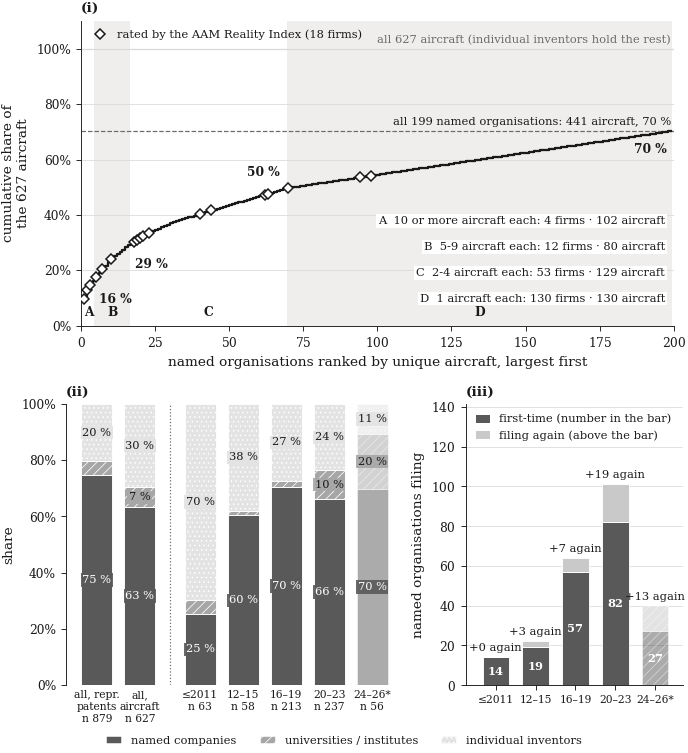

In [6]:
sizes = frames.firm_sizes(v)
n_air = len(v)
cum = (sizes.cumsum() / n_air).to_numpy()
rank = np.arange(1, len(sizes) + 1)
rated_firms = set(frames.ari_firms(v, cfg)['company'])
rated_rank = [i + 1 for i, f in enumerate(sizes.index) if f in rated_firms]
edges = [0] + cov['cumulative firms'].astype(int).tolist()
BAND = 'ABCD'
FT = ['Named company', 'University / institute', 'Individual inventor']
FT_NAME = {'Named company': 'named companies', 'University / institute': 'universities / institutes', 'Individual inventor': 'individual inventors'}
fig = plt.figure(figsize=(W, 6.9), constrained_layout=True)
top, bot = fig.subfigures(2, 1, height_ratios=[1.0, 1.0])
ax = top.subplots()
for k in range(1, len(edges) - 1, 2):                       # every second band shaded, to tell the bands apart
    ax.axvspan(edges[k] + 0.5, edges[k + 1] + 0.5, color=plots.FEW_FILL, linewidth=0, zorder=0)
ax.step(rank, cum, where='post', color=style.INK, linewidth=1.5, zorder=3)
ax.plot(rated_rank, cum[np.array(rated_rank) - 1], linestyle='none', marker='D', markersize=4.6, markerfacecolor='white', markeredgecolor=style.INK,
        markeredgewidth=1.0, zorder=5)
for k, (x0, x1) in enumerate(zip(edges[:-1], edges[1:])):
    ax.text((x0 + x1) / 2 + 0.5, 0.025, BAND[k], ha='center', va='bottom', fontsize=8, fontweight='bold')
    y1 = float(cum[x1 - 1])
    dx, dy, ha, va = [(4, -8, 'left', 'top'), (4, -8, 'left', 'top'), (-4, 6, 'right', 'bottom'), (-3, -8, 'right', 'top')][k]
    ax.annotate(pct(y1), (x1, y1), textcoords='offset points', xytext=(dx, dy), ha=ha, va=va, fontsize=8, fontweight='bold')
share_named = float(sizes.sum() / n_air)
ax.axhline(share_named, color=style.MUTED, linewidth=0.8, linestyle='--', zorder=2)
ax.text(len(sizes), share_named + 0.015, f"all {len(sizes)} named organisations: {int(sizes.sum())} aircraft, {pct(share_named)}", ha='right', va='bottom', fontsize=7.5)
ax.axhline(1, color=style.GRID, linewidth=0.8, zorder=1)
ax.text(len(sizes), 1.012, f"all {n_air} aircraft (individual inventors hold the rest)", ha='right', va='bottom', fontsize=7.5, color=style.MUTED)
band_text = ['10 or more aircraft each', '5-9 aircraft each', '2-4 aircraft each', '1 aircraft each']
for k, r in cov.reset_index(drop=True).iterrows():
    ax.text(0.985, 0.36 - 0.085 * k, f"{BAND[k]}  {band_text[k]}: {int(r['firms'])} firms · {int(r['aircraft'])} aircraft", transform=ax.transAxes, ha='right', va='top', fontsize=7.5,
            bbox=dict(fc='white', ec='none', pad=1.2))
ax.legend(handles=[Line2D([], [], linestyle='none', marker='D', markersize=4.6, markerfacecolor='white', markeredgecolor=style.INK, label=f"rated by the AAM Reality Index ({len(rated_rank)} firms)")],
          loc='upper left', fontsize=7.5, handletextpad=0.4, borderaxespad=0.3)
ax.set_xlim(0, len(sizes) + 1); ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0)); ax.grid(axis='y', color=style.GRID, linewidth=0.5); ax.set_axisbelow(True)
ax.set_xlabel('named organisations ranked by unique aircraft, largest first')
ax.set_ylabel(f"cumulative share of\nthe {n_air} aircraft"); style.mark(ax, '(i)')
# (ii) the filer types
a2, a3 = bot.subplots(1, 2, gridspec_kw={'width_ratios': [1.55, 1.0]})
win_counts = [v[v['window'] == w]['filer'].value_counts().reindex(FT).fillna(0) for w in WIN_NAMES]
rep_counts = fmr.set_index('filer')['representative patents']
parts = pd.DataFrame([[rep_counts['Named companies'], rep_counts['Universities and institutes'], rep_counts['Individual inventors']],
                      list(v['filer'].value_counts().reindex(FT).fillna(0))] + [list(c) for c in win_counts], columns=FT)
pos = [0, 1] + [2.4 + k for k in range(len(WIN_NAMES))]
parts_n = parts.sum(axis=1).astype(int).to_numpy()
plots.stack_bars(a2, parts, plots.FILER_STYLE, positions=pos, width=0.72, partial=[len(parts) - 1], min_label=0.06)
a2.axvline(1.7, color=style.MUTED, linewidth=0.8, linestyle=':')
a2.set_xticks(pos, [f"{t}\nn {n}" for t, n in zip(['all, repr.\npatents', 'all,\naircraft'] + [WSHORT[w] for w in WIN_NAMES], parts_n)], fontsize=7)
a2.set_ylim(0, 1); a2.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0)); a2.set_ylabel('share'); style.mark(a2, '(ii)')
a2.spines[['bottom']].set_visible(False); a2.tick_params(axis='x', length=0)
# (iii) the organisations per window
new, cont = fw['new firms'].to_numpy(), fw['continuing firms'].to_numpy()
x3 = np.arange(len(fw))
b1 = a3.bar(x3, new, 0.66, color=plots.ENTRY_COLORS[0], edgecolor='white', linewidth=0.6, zorder=3)
b2 = a3.bar(x3, cont, 0.66, bottom=new, color=plots.ENTRY_COLORS[1], edgecolor='white', linewidth=0.6, zorder=3)
for i, (p1, p2) in enumerate(zip(b1, b2)):
    if i == len(fw) - 1:
        for b in (p1, p2):
            b.set_alpha(0.5); b.set_hatch(style.PARTIAL_HATCH)
    a3.text(i, new[i] / 2, f"{new[i]}", ha='center', va='center', fontsize=7.5, color='white', fontweight='bold', zorder=5)
    a3.text(i, new[i] + cont[i] + 2, f"+{cont[i]} again", ha='center', va='bottom', fontsize=7.5)
a3.set_xticks(x3, [WSHORT[w] for w in WIN_NAMES], fontsize=7)
a3.set_xlim(-0.75, len(fw) - 0.3); a3.set_ylim(0, float((new + cont).max()) * 1.4); a3.set_ylabel('named organisations filing')
a3.grid(axis='y', color=style.GRID, linewidth=0.5); a3.set_axisbelow(True); style.mark(a3, '(iii)')
a3.legend(handles=[Patch(facecolor=plots.ENTRY_COLORS[0], label='first-time (number in the bar)'), Patch(facecolor=plots.ENTRY_COLORS[1], label='filing again (above the bar)')],
          loc='upper left', fontsize=7.5, handlelength=1.2)
bot.legend(handles=[Patch(facecolor=plots.FILER_STYLE[k][0], hatch=plots.FILER_STYLE[k][1], edgecolor='white', label=FT_NAME[k]) for k in FT], loc='outside lower center', ncol=3, fontsize=7.5, handlelength=1.4)
plt.show()
fig16_data = pd.concat([cov.assign(panel='(i) bands'), parts.assign(bar=['all, repr. patents', 'all, aircraft'] + WIN_NAMES, panel='(ii)'), fw.assign(panel='(iii)')], ignore_index=True)
save.figure(fig, cfg, 'q4', 'fig_16_who_files', data=fig16_data,
            caption='who files the eVTOL patents: (i) how much of the labelled dataset the largest named organisations hold; (ii) the filer types over all years, in representative patents and in aircraft, and per priority window; (iii) the named organisations filing in each window, split into first-time filers (the number inside the dark bar) and firms that filed in an earlier window ("+N again" above the bar).',
            source='PatSeer (assignee, priority date) · human labelling · AAM Reality Index (the firms it has rated)',
            unit=f"(i) and (ii): unique aircraft ({n_air}), and in (ii) the {int(parts_n[0])} representative patents, each once; (iii) the named organisation; the window 2024-26 is still filling (faded, star)",
            read="(i) The curve climbs by one firm at a time, largest first; the four bands A to D cut it where firms hold 10 or more, 5-9, 2-4 and 1 aircraft each; the cumulative share is printed at the end of each band; the dashed line is the share all named organisations hold; hollow diamonds are the firms the index rates. (ii) Each bar is 100 %; a segment of 6 % or more prints its share. The first bar counts patents (the unit changes the answer little), the others aircraft. (iii) Dark: organisations whose earliest aircraft in the corpus falls in the window; light: organisations that filed in an earlier window.",
            panels={'(i)': 'cumulative share of aircraft by named organisation', '(ii)': 'filer type, all years and per window', '(iii)': 'first-time and returning organisations per window'})
plt.close(fig)

### Can one filer decide a class share?

`frames.class_concentration_brief` reads, for each class of 20 aircraft or more, its filers (a firm; an individual inventor's patent is its own filer), the effective number of filers (`lib.concentration.inverse_hhi` = 1 / Σ sᵢ², through `class_filer_concentration`), the largest filer over all years and the largest share one filer holds inside a single complete window of 10 aircraft or more of the class. `frames.firm_leverage_table` (`lib.concentration.firm_leverage`) removes, one firm at a time, every firm of 3 aircraft or more and keeps the class share that moves most, over all years and inside a window of 30 aircraft or more; `frames.firm_leverage_classes` keeps every class's move for the eight firms that move a share most (`lib.concentration.share_shift_when_dropped`), the reading of the "what largest change means" paragraph. All three are checked against the document.

In [7]:
cb = frames.class_concentration_brief(v, COMPLETE)
lev = frames.firm_leverage_table(v, WIN_NAMES)
levc = frames.firm_leverage_classes(v, WIN_NAMES, lev=lev)
verify(cb, 'la_class_concentration_brief', key=['code'])
verify(lev, 'la_firm_leverage', key=['firm'])
verify(levc, 'la_firm_leverage_classes', key=['firm', 'class'], doc_wording=False)
save.table(cb, cfg, 'q4', 'tab_class_concentration', caption='The classes of 20 aircraft or more: filers, effective number of filers, the largest filer over all years and inside one priority window.',
           source='PatSeer (assignee, priority date) · human labelling · unit: unique aircraft')
save.table(lev, cfg, 'q4', 'tab_firm_leverage', caption='The largest change of a class share when one firm (3 aircraft or more) is removed, over all years and inside one priority window.',
           source='PatSeer (assignee, priority date) · human labelling · unit: unique aircraft')
display(cb); lev.head(10)

,la_class_concentration_brief
table,la_class_concentration_brief
rows (notebook | document),7 | 7
cells compared,91
matched,91
expected differences,0
differences,0
status,match


,la_firm_leverage
table,la_firm_leverage
rows (notebook | document),31 | 31
cells compared,279
matched,279
expected differences,0
differences,0
status,match


,la_firm_leverage_classes
table,la_firm_leverage_classes
rows (notebook | document),96 | 96
cells compared,1056
matched,1056
expected differences,0
differences,0
status,match


,class,code,aircraft,filers,effective filers,largest filer,its aircraft,its share,top 3 share,largest share inside one window,held by,in window,window aircraft,its aircraft in the window
0,Lift + Cruise,SLC,165,105,57.1,Airbus,12,0.073,0.139,0.294,an individual inventor's patent,<= 2011,17,5
1,Tilt Propulsor,TR,151,100,24.8,Bell / Textron,27,0.179,0.225,0.340,Bell / Textron,2016-19,50,17
2,Combined Vectored Thrust,CVT,106,67,24.3,Bell / Textron,17,0.160,0.255,0.214,Bell / Textron,2016-19,28,6
3,Tilt Wing,TW,56,43,24.9,Bell / Textron,8,0.143,0.232,0.211,Bell / Textron,2020-23,19,4
4,Multirotor,MR,48,36,26.2,Airbus,4,0.083,0.229,0.250,Airbus,2016-19,16,4
5,Pitch-to-Cruise,PTC,25,21,17.9,Airbus,3,0.120,0.280,0.250,Airbus,2016-19,12,3
6,Tilt Body,TB,24,20,13.1,Bell / Textron,5,0.208,0.292,0.333,Bell / Textron,2016-19,12,4


,firm,unique aircraft,share of the analysis set,class most moved,shift if the firm is dropped (pp),largest shift inside one window (pp),that window,that class,modal class,shift magnitude (pp)
0,Bell / Textron,60,0.096,SLC,2.63,5.2,2016-19,TR,TR,2.63
1,Airbus,21,0.033,SLC,-1.07,3.0,2012-15,SLC,SLC,1.07
2,Leonardo,9,0.014,CVT,-0.73,1.1,<= 2011,TR,CVT,0.73
3,Honda,9,0.014,SLC,-0.59,1.8,2020-23,SLC,SLC,0.59
4,Aurora Flight Sciences,7,0.011,SLC,-0.51,1.4,2016-19,SLC,SLC,0.51
5,Shenfeng Aviation,10,0.016,SLC,-0.47,1.6,2016-19,SLC,SLC,0.47
6,Lilium,7,0.011,CVT,-0.46,1.5,2012-15,CVT,CVT,0.46
7,DeLorean Aerospace,5,0.008,TR,-0.45,4.3,2012-15,TR,TR,0.45
8,Zuri,5,0.008,SLC,-0.43,1.0,2020-23,SLC,SLC,0.43
9,Archer Aviation,4,0.006,CVT,-0.37,0.9,2020-23,CVT,CVT,0.37


### Figure 17 — whether one filer holds enough of a class to decide its share

(i) Per class of 20 aircraft or more, the share held by its largest filer over all years (bar) and the highest share one filer reaches inside a single priority window (diamond; windows with 10 or more aircraft of the class, 2024-26 left out); on the tick, the class's filers and its effective number of filers. (ii) The eight firms that move a class share most when removed: over all years (bar, coloured by the class that moves) and inside one window of 30 aircraft or more (diamond).

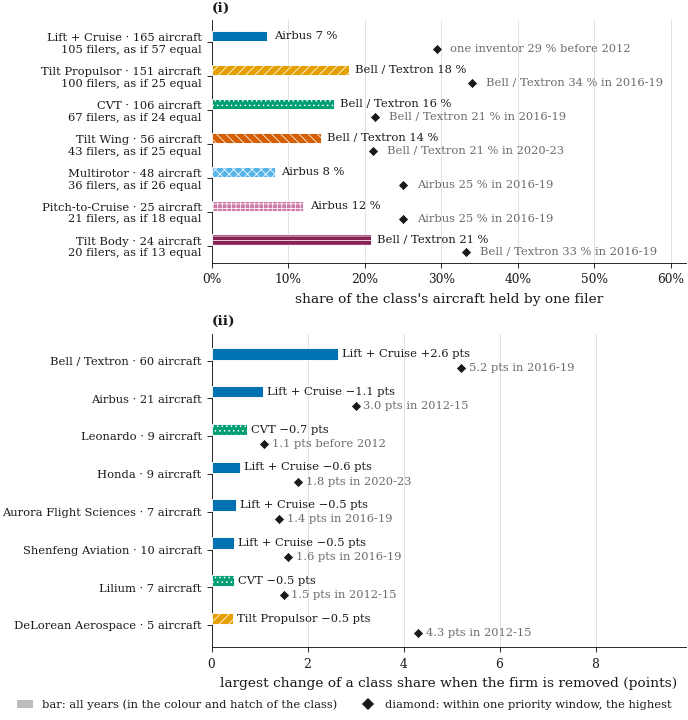

In [8]:
WORD = lambda c: 'CVT' if c == 'CVT' else style.cls(c).name
who_short = lambda s: str(s).replace("an individual inventor's patent", 'one inventor')
winlab = lambda w: 'before 2012' if w == '<= 2011' else f"in {w}"
fig, (a1, a2) = plt.subplots(2, 1, figsize=(W, 6.6), constrained_layout=True, gridspec_kw={'height_ratios': [len(cb), 8 + 1]})
dia = dict(marker='D', s=24, color=style.INK, edgecolor='white', linewidth=0.6, zorder=5)
for i, r in cb.reset_index(drop=True).iterrows():
    s = style.cls(r['code'])
    a1.barh(i - 0.18, r['its share'], 0.3, color=s.color, hatch=s.hatch, edgecolor='white', linewidth=0.6, zorder=3)
    a1.text(r['its share'] + 0.008, i - 0.18, f"{who_short(r['largest filer'])} {pct(r['its share'])}", va='center', fontsize=7.5)
    a1.scatter(r['largest share inside one window'], i + 0.2, **dia)
    a1.text(r['largest share inside one window'] + 0.018, i + 0.2, f"{who_short(r['held by'])} {pct(r['largest share inside one window'])} {winlab(r['in window'])}", va='center', fontsize=7.5, color=style.MUTED)
a1.set_yticks(range(len(cb)), [f"{WORD(c)} · {int(n)} aircraft\n{int(f)} filers, as if {e:.0f} equal" for c, n, f, e in zip(cb['code'], cb['aircraft'], cb['filers'], cb['effective filers'])], fontsize=7.5)
a1.invert_yaxis(); a1.set_xlim(0, 0.62); a1.xaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
a1.set_xlabel("share of the class's aircraft held by one filer"); a1.grid(axis='x', color=style.GRID, linewidth=0.5); a1.set_axisbelow(True); style.mark(a1, '(i)')
l8 = lev.head(8).reset_index(drop=True)
for i, r in l8.iterrows():
    s = style.cls(r['class most moved'])
    a2.barh(i - 0.18, r['shift magnitude (pp)'], 0.3, color=s.color, hatch=s.hatch, edgecolor='white', linewidth=0.6, zorder=3)
    sign = '+' if r['shift if the firm is dropped (pp)'] > 0 else '−'
    a2.text(r['shift magnitude (pp)'] + 0.08, i - 0.18, f"{WORD(r['class most moved'])} {sign}{r['shift magnitude (pp)']:.1f} pts", va='center', fontsize=7.5)
    a2.scatter(r['largest shift inside one window (pp)'], i + 0.2, **dia)
    a2.text(r['largest shift inside one window (pp)'] + 0.16, i + 0.2, f"{r['largest shift inside one window (pp)']:.1f} pts {winlab(r['that window'])}", va='center', fontsize=7.5, color=style.MUTED)
a2.set_yticks(range(len(l8)), [f"{f} · {int(n)} aircraft" for f, n in zip(l8['firm'], l8['unique aircraft'])], fontsize=7.5)
a2.invert_yaxis(); a2.set_xlim(0, float(max(l8['largest shift inside one window (pp)'].max(), l8['shift magnitude (pp)'].max())) * 1.9)
a2.set_xlabel('largest change of a class share when the firm is removed (points)'); a2.grid(axis='x', color=style.GRID, linewidth=0.5); a2.set_axisbelow(True); style.mark(a2, '(ii)')
fig.legend(handles=[Patch(facecolor='#bdbdbd', label='bar: all years (in the colour and hatch of the class)'), Line2D([], [], linestyle='none', **{k: dia[k] for k in ('marker',)}, markersize=5, color=style.INK, label='diamond: within one priority window, the highest')],
           loc='outside lower center', ncol=2, fontsize=7.5, handlelength=1.4)
plt.show()
fig17_data = pd.concat([cb.assign(panel='(i)'), l8.assign(panel='(ii)')], ignore_index=True)
save.figure(fig, cfg, 'q4', 'fig_17_one_filer', data=fig17_data,
            caption='whether one filer holds enough of a class to decide its share: (i) the largest filer of each class over all years (bar) and its highest share within a single priority window (diamond), with the effective number of filers; (ii) the weight of a single firm: removing one firm at a time, how far each class share moves.',
            source='PatSeer (assignee, priority date) · human labelling',
            unit=f"unique aircraft; (i) the {len(cb)} classes of {frames.CH4_CLASS_MIN} aircraft or more, windows of {frames.CH4_CELL_MIN} aircraft or more, 2024-26 left out; (ii) firms of {frames.LEVERAGE_MIN_FIRM} aircraft or more, the eight that move a class share most, windows of {frames.LEVERAGE_MIN_WINDOW} aircraft or more",
            read="(i) Bar: the share of the class's aircraft held by its largest filer over all years, named at the bar's end; diamond: the highest share one filer holds inside a single complete priority window, with the filer and the window. On the tick: the class's aircraft, its filers and its effective number of filers, 1 / Σ sᵢ² (how many equally sized filers would give the same concentration). (ii) Removing a firm takes its aircraft out of every class it files in and recomputes every share; the class that moves most is the one drawn, in its colour, with the move in percentage points (+ = the share rises when the firm is removed). Diamond: the largest move inside one window.",
            panels={'(i)': 'largest filer of each class, all years and within one window', '(ii)': 'the weight of a single firm: removing one firm at a time'})
plt.close(fig)

### What the AAM Reality Index adds

`frames.ari_funding_frame` lists the index firms that file in the corpus (18) with the disclosed funding of the May 2026 release (US$ million; *corporate backed* and earlier-release firms have no amount), their unique aircraft, first patent, first flight and the lead from first patent to first flight (flights up to the release year, 2026). `frames.ari_funding_tests` gives the Spearman ρ and p (`lib.association.spearman_rho_p`) of funding against aircraft, first patent and lead, on the firms with an amount (the lead on those whose first flight has happened). Both are checked against the document.

In [9]:
fund = frames.ari_funding_frame(v, cfg)
ftests = frames.ari_funding_tests(fund)
verify(fund, 'la_ari_funding', key=['company'])
verify(ftests, 'la_ari_funding_tests', key=['column'])
save.table(fund, cfg, 'q4', 'tab_ari_funding', caption='The AAM Reality Index firms that file here: disclosed funding, aircraft, first patent and lead to first flight.',
           source='AAM Reality Index (May 2026 release) · PatSeer · human labelling')
save.table(ftests, cfg, 'q4', 'tab_ari_funding_tests', caption='Spearman rank correlation of disclosed funding against three patent-side quantities, on the funded firms.',
           source='AAM Reality Index (May 2026 release) · PatSeer · human labelling')
display(fund); ftests

,la_ari_funding
table,la_ari_funding
rows (notebook | document),18 | 18
cells compared,162
matched,162
expected differences,0
differences,0
status,match


,la_ari_funding_tests
table,la_ari_funding_tests
rows (notebook | document),3 | 3
cells compared,12
matched,12
expected differences,0
differences,0
status,match


,company,ARI score,release,funding $M,funding status,unique aircraft,first patent,first flight,first flight flown,years first patent to first flight
0,Volocopter,8.10,May 2026,NaN,"corporate backed, no amount",4,2019,2021.0,True,2.0
1,Wollant Aviation,8.05,May 2026,701.0,disclosed,2,2022,2023.0,True,1.0
2,Joby Aviation,8.00,May 2026,5181.4,disclosed,8,2013,2018.0,True,5.0
3,Beta Technologies,7.95,May 2026,2952.7,disclosed,1,2021,2020.0,True,-1.0
4,AutoFlight,7.85,May 2026,640.0,disclosed,2,2019,2022.0,True,3.0
5,Archer Aviation,7.80,May 2026,2864.2,disclosed,4,2020,2023.0,True,3.0
6,Embraer / Eve,7.80,May 2026,1002.6,disclosed,4,2018,2025.0,True,7.0
7,Airbus,7.60,December 2024,NaN,not in the May 2026 release,21,2015,NaN,False,NaN
8,Wisk Aero,7.55,May 2026,NaN,"corporate backed, no amount",4,2020,2025.0,True,5.0
9,Wofei / Geely Aviation,7.50,May 2026,238.4,disclosed,2,2024,2023.0,True,-1.0


,against,column,firms,rho,p
0,unique aircraft in the corpus,unique aircraft,9,0.56,0.114
1,priority year of the first patent,first patent,9,-0.71,0.031
2,years from first patent to first flight,years first patent to first flight,8,0.48,0.230


### Figure 18 — funding against the aircraft filed and the patent-to-flight lead

The nine firms with a disclosed amount: funding (US$ million, log scale) against (i) their unique aircraft in the corpus and (ii) the lead from first patent to first flight, on the eight firms whose first flight has happened. ρ is the Spearman score of the statistics box of chapter 1.

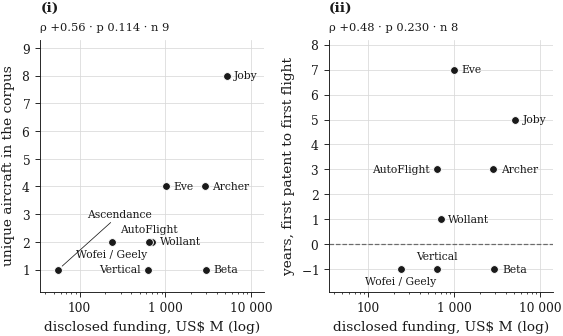

In [10]:
ARI_SHORT = {'Ascendance Flight Technologies': 'Ascendance', 'Wofei / Geely Aviation': 'Wofei / Geely', 'Embraer / Eve': 'Eve', 'Beta Technologies': 'Beta',
             'Vertical Aerospace': 'Vertical', 'Wollant Aviation': 'Wollant', 'Archer Aviation': 'Archer', 'Joby Aviation': 'Joby'}
d18 = fund[fund['funding $M'].notna()]
fig, axs = plt.subplots(1, 2, figsize=(W * 0.82, 3.1), constrained_layout=True)
for ax, (col, ylab, mk) in zip(axs, (('unique aircraft', 'unique aircraft in the corpus', '(i)'), ('years first patent to first flight', 'years, first patent to first flight', '(ii)'))):
    s = d18[['company', 'funding $M', col]].dropna()
    ax.scatter(s['funding $M'], s[col], s=26, color=style.INK, edgecolor='white', linewidth=0.6, zorder=4)
    ax.set_xscale('log'); ax.set_xlim(35, 14000)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x_, _p: f"{x_:,.0f}".replace(',', ' ')))
    ax.set_xlabel('disclosed funding, US$ M (log)'); ax.set_ylabel(ylab)
    ax.grid(color=style.GRID, linewidth=0.5); ax.set_axisbelow(True)
    if col.startswith('years'):
        ax.axhline(0, color=style.MUTED, linewidth=0.8, linestyle='--', zorder=2)
        ax.set_ylim(-1.9, 8.2); ax.yaxis.set_major_locator(mticker.MultipleLocator(1))
    else:
        ax.set_ylim(0.2, 9.3); ax.yaxis.set_major_locator(mticker.MultipleLocator(1))
    t = ftests[ftests['column'] == col].iloc[0]
    ax.set_title(f"ρ {t['rho']:+.2f} · p {t['p']:.3f} · n {int(t['firms'])}".replace('-', '−'), fontsize=7.5, loc='left')
    style.mark(ax, mk, lines_up=1.1)
fig.canvas.draw()
for ax, col in zip(axs, ('unique aircraft', 'years first patent to first flight')):
    s = d18[['company', 'funding $M', col]].dropna()
    failed = plots.place_labels(ax, s['funding $M'].to_numpy(), s[col].to_numpy(), [ARI_SHORT.get(c, c) for c in s['company']], [3.4] * len(s), fontsize=7)
    assert not failed, failed
plt.show()
save.figure(fig, cfg, 'q4', 'fig_18_ari_funding', data=d18,
            caption='the AAM Reality Index firms with a disclosed funding amount: funding against the aircraft they filed (i) and the lead from first patent to first flight (ii); ρ is the Spearman score of the statistics box (chapter 1).',
            source='AAM Reality Index (May 2026 release: disclosed funding, first flight) · PatSeer (priority date) · human labelling',
            unit='the firm: the nine AAM Reality Index firms with a disclosed funding amount; (ii) the eight whose first flight has happened (up to the release year, 2026); a lead below zero means the firm\'s earliest filing is not in this corpus',
            read="One dot per firm. Horizontal: disclosed funding in US$ million on a log scale. (i) Vertical: the firm's unique aircraft in the corpus. (ii) Vertical: the years from the firm's first patent to its first flight (below the dashed line: the first flight is dated before the first patent in this corpus). Above each panel: Spearman ρ (+1 when more funding always goes with a larger value, 0 when unrelated, −1 when it always goes with a smaller one), its p and the number of firms. On so few firms only a strong relation can be detected.",
            panels={'(i)': 'funding against unique aircraft', '(ii)': 'funding against the lead from first patent to first flight'})
plt.close(fig)

### 4.1 numbers

The counts and shares of the Method and of the Results, each written the way the document prints it. The two numbers of chapter 2 that 4.1's Answer quotes (the median filers per aircraft in the core and in the rim of Figure 8, and the CVT archetype with 5-6 propulsor units) come from `frames.zones`, `frames.zone_core` and `frames.archetype_filer_split`; the external comparison (the two best-funded firms' share of the disclosed funding against their share of the aircraft) from `frames.ari_f_funding`.

In [11]:
fmi = fm.set_index('filer')
zones = frames.zones(v, WIN_NAMES, cfg.analysis['zone_min_aircraft'])
zz = zones[pd.to_numeric(zones['filers 2016-23']) > 0]
fpa, sh = zz['filers per aircraft'], zz['share 2016-23']
core_fpa = fpa[frames.zone_core(zones).reindex(zz.index).fillna(False).astype(bool)]
rim_fpa = fpa[sh <= sh.median()]
fs = frames.archetype_filer_split(v, cfg.analysis['filer_panel_min_aircraft']).set_index('archetype').loc['CVT · 5-6']
ext = frames.ari_f_funding(ds, v, cfg)
firms_ext = ext[ext['kind'] == 'firm']
top2 = firms_ext.nlargest(2, 'funding $M')
fwi = fw.set_index('window')
disc = fund['funding status'].eq('disclosed')
tt = ftests.set_index('column')
N1 = {'unique_s': thin(len(v)), 'c4_rep_n': thin(fmr.set_index('filer').loc['all filers', 'representative patents']),
      'c4_class_min': str(frames.CH4_CLASS_MIN), 'c4_cell_min': str(frames.CH4_CELL_MIN),
      'c4_co_share': pct(fmi.loc['Named companies', 'unique aircraft'] / len(v)), 'c4_uni_share': pct(fmi.loc['Universities and institutes', 'unique aircraft'] / len(v)),
      'c4_ind_share': pct(fmi.loc['Individual inventors', 'unique aircraft'] / len(v)),
      'c4_top4_n': str(int(cov.iloc[0]['firms'])), 'c4_top4_share': pct(cov.iloc[0]['aircraft'] / len(v)),
      'c4_single_n': str(int(cov.iloc[-1]['firms'])), 'c4_org_n': str(int(cov.iloc[-1]['cumulative firms'])),
      'c4_org_share': pct(cov.iloc[-1]['cumulative aircraft'] / len(v)),
      'c4_ind_w1': pct(fwi.loc['<= 2011', 'share individual inventors']), 'c4_ind_w4': pct(fwi.loc['2020-23', 'share individual inventors']),
      'c4_new_1619': str(int(fwi.loc['2016-19', 'new firms'])), 'c4_cont_1619': str(int(fwi.loc['2016-19', 'continuing firms'])),
      'c4_new_2023': str(int(fwi.loc['2020-23', 'new firms'])), 'c4_cont_2023': str(int(fwi.loc['2020-23', 'continuing firms'])),
      'c4_conc_n': str(len(cb)), 'c4_max_top_share': pct(cb['its share'].max()), 'c4_min_eff': f"{cb['effective filers'].min():.0f}",
      'c4_lev1_pp': f"{lev.iloc[0]['shift magnitude (pp)']:.1f}",
      'c4_ari_n': str(len(fund)), 'c4_ari_air': str(int(fund['unique aircraft'].sum())), 'c4_ari_share': pct(fund['unique aircraft'].sum() / len(v)),
      'c4_fund_n': str(int(disc.sum())), 'c4_corp_n': str(int(fund['funding status'].str.startswith('corporate').sum())),
      'c4_hist_n': str(int(fund['funding status'].str.startswith('not in').sum())),
      'c4_lead_n': str(int(tt.loc['years first patent to first flight', 'firms'])),
      'c4_rho_fp': f"{tt.loc['first patent', 'rho']:+.2f}", 'c4_p_fp': pval(tt.loc['first patent', 'p']),
      'c4_core_fpa': f"{core_fpa.median():.2f}", 'c4_rim_fpa': f"{rim_fpa.median():.2f}",
      'sm_cvt56_air': str(int(fs['aircraft'])), 'sm_cvt56_top': fs['largest filer'], 'sm_cvt56_top_n': str(int(fs['its aircraft'])),
      'sm_ext_top1': top2.iloc[0]['company'], 'sm_ext_top2': top2.iloc[1]['company'],
      'sm_ext_top2_fundshare': pct(top2['funding $M'].sum() / firms_ext['funding $M'].sum()),
      'sm_ext_top2_airshare': pct1(top2['unique aircraft'].sum() / v['aircraft_id'].nunique())}
numbers_check(N1)

,name,notebook,document,match
0,unique_s,627,627,yes
1,c4_rep_n,879,879,yes
2,c4_class_min,20,20,yes
3,c4_cell_min,10,10,yes
4,c4_co_share,63 %,63 %,yes
5,c4_uni_share,7 %,7 %,yes
6,c4_ind_share,30 %,30 %,yes
7,c4_top4_n,4,4,yes
8,c4_top4_share,16 %,16 %,yes
9,c4_single_n,130,130,yes


In [12]:
# also quoted in the takeaways of 4.1 (not in the document's number list): each against the figure the document prints
cbi = cb.set_index('code')
levi = lev.set_index('firm')
bell, airbus = 'Bell / Textron', 'Airbus'
bell_cls = levc[levc['firm'] == bell].set_index('class')
airbus_cls = levc[levc['firm'] == airbus].set_index('class')
fmri = fmr.set_index('filer')
EXTRA1 = {
    'aircraft held by the 4 firms of 10+': (str(int(cov.iloc[0]['aircraft'])), '102'), 'aircraft held by the next 12': (f"{int(cov.iloc[0]['firms'])}/{int(cov.iloc[1]['firms'])}/{int(cov.iloc[1]['aircraft'])}", '4/12/80'),
    'named companies, individuals, universities (aircraft)': (f"{int(fmi.loc['Named companies', 'unique aircraft'])} / {int(fmi.loc['Individual inventors', 'unique aircraft'])} / {int(fmi.loc['Universities and institutes', 'unique aircraft'])}", '397 / 186 / 44'),
    'companies and individuals over representative patents': (f"{pct(fmri.loc['Named companies', 'share per representative patent'])} / {pct(fmri.loc['Individual inventors', 'share per representative patent'])}", '75 % / 20 %'),
    'largest holdings: Tilt Body, Tilt Propulsor, CVT': (f"{pct(cbi.loc['TB', 'its share'])} / {pct(cbi.loc['TR', 'its share'])} / {pct(cbi.loc['CVT', 'its share'])}", '21 % / 18 % / 16 %'),
    'filer of those three': (' / '.join(cbi.loc[c, 'largest filer'] for c in ('TB', 'TR', 'CVT')), 'Bell / Textron / Bell / Textron / Bell / Textron'),
    'effective filers of the four largest classes (smallest)': (f"{cb.sort_values('aircraft', ascending=False).head(4)['effective filers'].min():.0f}", '24'),
    'effective filers of Lift + Cruise': (f"{cbi.loc['SLC', 'effective filers']:.0f}", '57'),
    'Bell / Textron share of Tilt Propulsor in 2016-19': (f"{pct(cbi.loc['TR', 'largest share inside one window'])} in {cbi.loc['TR', 'in window']}", '34 % in 2016-19'),
    'one inventor, Lift + Cruise, window and its aircraft': (f"{pct(cbi.loc['SLC', 'largest share inside one window'])} in {cbi.loc['SLC', 'in window']}, {int(cbi.loc['SLC', 'window aircraft'])} aircraft", '29 % in <= 2011, 17 aircraft'),
    'Bell / Textron: Lift + Cruise share rises (pts)': (f"{bell_cls.loc['SLC', 'shift all years (pp)']:.1f}", '2.6'),
    'Bell / Textron lowers Tilt Propulsor, CVT, Tilt Wing (pts)': (' / '.join(f"{abs(bell_cls.loc[c, 'shift all years (pp)']):.1f}" for c in ('TR', 'CVT', 'TW')), '2.2 / 1.2 / 0.5'),
    'Bell / Textron Lift + Cruise aircraft': (str(int(bell_cls.loc['SLC', 'firm aircraft in the class'])), '1'),
    'second firm and its move (pts)': (f"{lev.iloc[1]['firm']} {lev.iloc[1]['shift magnitude (pp)']:.1f}", 'Airbus 1.1'),
    'Airbus: Lift + Cruise aircraft of its total': (f"{int(airbus_cls.loc['SLC', 'firm aircraft in the class'])} of {int(airbus_cls.loc['SLC', 'firm aircraft'])}", '12 of 21'),
    'largest move inside one window (pts, firm, window)': (f"{lev['largest shift inside one window (pp)'].max():.1f} {lev.loc[lev['largest shift inside one window (pp)'].idxmax(), 'firm']} {lev.loc[lev['largest shift inside one window (pp)'].idxmax(), 'that window']}", '5.2 Bell / Textron 2016-19'),
    'Airbus move in 2012-15 (pts) and its window aircraft': (f"{abs(airbus_cls.loc['SLC', 'shift 2012-15 (pp)']):.1f}, {int(airbus_cls.loc['SLC', 'window aircraft 2012-15'])}", '3.0, 58'),
    'best-funded firm, its amount and first patent': (f"{d18.sort_values('funding $M').iloc[-1]['company']} {thin(d18['funding $M'].max())} {int(d18.sort_values('funding $M').iloc[-1]['first patent'])}", 'Joby Aviation 5 181 2013'),
    'funding against aircraft: rho, p': (f"{tt.loc['unique aircraft', 'rho']:+.2f}, p {tt.loc['unique aircraft', 'p']:.2f}", '+0.56, p 0.11'),
    'funding against lead: rho, p, n': (f"{tt.loc['years first patent to first flight', 'rho']:+.2f}, p {tt.loc['years first patent to first flight', 'p']:.2f}, {int(tt.loc['years first patent to first flight', 'firms'])}", '+0.48, p 0.23, 8'),
    'funding against first patent: p': (f"p {tt.loc['first patent', 'p']:.3f}", 'p 0.031'),
    'CVT 5-6: filers hold one each': (str(int(fs['filers holding one aircraft'])), '12'),
}
extra1 = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if checks._norm(m) == checks._norm(d) else 'NO'} for k, (m, d) in EXTRA1.items()])
extra1

,quoted,notebook,document,match
0,aircraft held by the 4 firms of 10+,102,102,yes
1,aircraft held by the next 12,4/12/80,4/12/80,yes
2,"named companies, individuals, universities (aircraft)",397 / 186 / 44,397 / 186 / 44,yes
3,companies and individuals over representative patents,75 % / 20 %,75 % / 20 %,yes
4,"largest holdings: Tilt Body, Tilt Propulsor, CVT",21 % / 18 % / 16 %,21 % / 18 % / 16 %,yes
5,filer of those three,Bell / Textron / Bell / Textron / Bell / Textron,Bell / Textron / Bell / Textron / Bell / Textron,yes
6,effective filers of the four largest classes (smallest),24,24,yes
7,effective filers of Lift + Cruise,57,57,yes
8,Bell / Textron share of Tilt Propulsor in 2016-19,34 % in 2016-19,34 % in 2016-19,yes
9,"one inventor, Lift + Cruise, window and its aircraft","29 % in <= 2011, 17 aircraft","29 % in <= 2011, 17 aircraft",yes


## 4.2 — How new are the sector's filers, do first-time or returning firms reshape the design space, and where does a firm's next design land?

#### Method

The design space moves when the classes of the new aircraft change. Two things can move it: the firms filing for the first time may choose other classes than the firms already filing, and a firm that files again may change class. Both are read on the named organisations only, because an individual inventor cannot be followed from one patent to the next (4.1).


- **First-time against returning filers: Figure 19 (i).** In each window the named organisations' aircraft are split into those of first-time filers and those of returning filers (defined in 4.1), and the class mix of the two groups is compared by a chi-square test over Lift + Cruise, Tilt Propulsor, CVT, Tilt Wing, Multirotor and the other classes together. Tested where the returning group holds 20 aircraft or more: 2016-19 and 2020-23. *Unit:* the unique aircraft.
- **Tilt Wing's entering firms: Figure 19 (ii).** Tilt Wing is read on its own because it is the class a firm's next aircraft leaves most often (Figure 20). Per window: the share of the firms entering the labelled dataset in that window whose first aircraft is a Tilt Wing (a firm enters once, in the window of its first aircraft; *unit:* the firm), beside Tilt Wing's share of all the window's aircraft (*unit:* the aircraft, individuals included). The change of that aircraft share from 2016-19 to 2020-23 is tested with Fisher's exact test. For the firms entering with Tilt Wing in 2020-23, the filer type and whether the firm filed any other aircraft are counted, against all the window's entering firms.
- **Where a firm's next aircraft lands: Figure 20.** A **succession** is a named organisation's aircraft followed by the same firm's next aircraft in priority order; aircraft of the same year are taken in the order of the labelled dataset, which is arbitrary. Each class of origin with 10 successions or more is one row, giving the share of the next aircraft that stay in the class and where the others go (the row sums to 100 %). *Unit:* the succession: 240 of them, from the 69 firms with two aircraft or more; a firm with many aircraft contributes many successions. Sources: PatSeer (assignee, priority date), human labelling.
- **Assumptions and limits.** The order of a firm's aircraft is the order of its architecture filings in this labelled dataset; filings outside its scope, such as patents on other aircraft or patents the search did not retrieve, could reorder a firm's sequence, and no outside source confirms the order.

### First-time against returning filers

`frames.named_entries` keeps the aircraft of named organisations that have a window and flags each as first-time (the firm's earliest window in the corpus is this window) or returning; the class is kept for Lift + Cruise, Tilt Propulsor, CVT, Tilt Wing and Multirotor, the rest is pooled. `frames.entry_split` gives the class mix of the two groups per complete window, `frames.entry_split_test` the chi-square p of class against group (`lib.association.chi2_p_of_crosstab`) where the returning group holds 20 aircraft or more, and again without the returning firm that holds most of them (a test added after the first result was seen). `frames.tw_entry` reads Tilt Wing's entering firms against its share of all aircraft, with Fisher's exact test (`lib.association.fisher_exact_p`) of the change from the window before. The three tables are checked against the document (the class columns print the document's names, Tilt Rotor for Tilt Propulsor).

In [13]:
DOCCLS = {'SLC': 'Lift + Cruise', 'TR': 'Tilt Rotor', 'CVT': 'CVT', 'TW': 'Tilt Wing', 'MR': 'Multirotor', 'other': 'other classes'}
ent = frames.named_entries(v, WIN_NAMES)
es = frames.entry_split(ent, COMPLETE, DOCCLS)
et = frames.entry_split_test(ent, COMPLETE)
twe = frames.tw_entry(v, COMPLETE)
verify(es, 'la_entry_split', key=['window', 'group'], doc_wording=False)
verify(et, 'la_entry_split_test', key=['window'], doc_wording=False)
verify(twe, 'la_tw_entry', key=['window'], doc_wording=False)
save.table(thesis_names(es), cfg, 'q4', 'tab_entry_split', caption='The class mix of the aircraft of first-time and returning named organisations, per priority window.',
           source='PatSeer (assignee, priority date) · human labelling · unit: unique aircraft')
save.table(et, cfg, 'q4', 'tab_entry_split_test', caption='Chi-square test of class against first-time or returning, in the windows where the returning group holds 20 aircraft or more, with and without the largest returning firm.',
           source='PatSeer (assignee, priority date) · human labelling · unit: unique aircraft')
save.table(twe, cfg, 'q4', 'tab_tilt_wing_entry', caption="Tilt Wing's entering firms against its share of all aircraft, per priority window.",
           source='PatSeer (assignee, priority date) · human labelling')
display(thesis_names(es)); display(et); twe

,la_entry_split
table,la_entry_split
rows (notebook | document),8 | 8
cells compared,64
matched,64
expected differences,0
differences,0
status,match


,la_entry_split_test
table,la_entry_split_test
rows (notebook | document),4 | 4
cells compared,28
matched,28
expected differences,0
differences,0
status,match


,la_tw_entry
table,la_tw_entry
rows (notebook | document),4 | 4
cells compared,44
matched,44
expected differences,0
differences,0
status,match


,window,group,aircraft,firms,Lift + Cruise,Tilt Propulsor,CVT,Tilt Wing,Multirotor,other classes
0,<= 2011,first-time filers,19,14,0.158,0.632,0.053,0.053,0.053,0.053
1,<= 2011,returning filers,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2012-15,first-time filers,30,19,0.200,0.267,0.200,0.133,0.100,0.100
3,2012-15,returning filers,6,3,0.167,0.500,0.333,0.000,0.000,0.000
4,2016-19,first-time filers,98,57,0.316,0.133,0.122,0.112,0.082,0.235
5,2016-19,returning filers,57,7,0.140,0.351,0.140,0.105,0.105,0.158
6,2020-23,first-time filers,120,82,0.342,0.217,0.150,0.092,0.067,0.133
7,2020-23,returning filers,61,19,0.311,0.230,0.295,0.098,0.000,0.066


,window,first-time aircraft,returning aircraft,returning firms,p,largest returning firm,its aircraft,p without it
0,<= 2011,19,0,0,NaN,NaN,NaN,NaN
1,2012-15,30,6,3,NaN,NaN,NaN,NaN
2,2016-19,98,57,7,0.016561,Bell / Textron,33.0,0.587153
3,2020-23,120,61,19,0.070088,Bell / Textron,22.0,0.380364


,window,firms entering,entering with Tilt Wing,Tilt Wing share of entrants,Tilt Wing entrants: universities / institutes,Tilt Wing entrants: no other aircraft,all entrants: universities / institutes,all entrants: no other aircraft,aircraft in the window,Tilt Wing aircraft,Tilt Wing share of the aircraft,"Tilt Wing share, Fisher p against the window before"
0,<= 2011,14,1,0.071,1,1,2,6,63,4,0.063,NaN
1,2012-15,19,2,0.105,0,1,1,11,58,6,0.103,0.518
2,2016-19,57,7,0.123,0,4,5,34,213,23,0.108,1.000
3,2020-23,82,9,0.110,3,6,15,56,237,19,0.080,0.334


### Figure 19 — who moves the class mix

(i) The classes of the aircraft of first-time and returning filers in the two windows that can be tested, with the chi-square p and the returning firm that holds most of the returning aircraft. (ii) Tilt Wing's share of the firms entering in each window (hatched; above it that share, then the firms entering with a Tilt Wing of all firms entering) beside its share of all the window's aircraft (grey; under each window, Tilt Wing aircraft over all the window's aircraft).

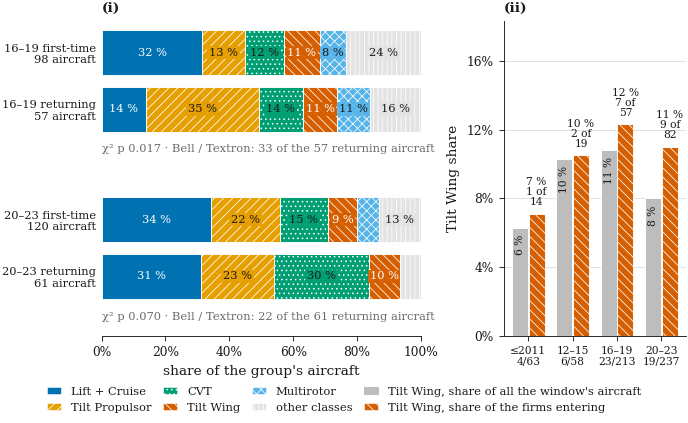

In [14]:
tested = et[et['p'].notna()]
codes19 = ['SLC', 'TR', 'CVT', 'TW', 'MR', 'other']
style19 = {c: (style.cls(c) if c != 'other' else ('#e3e3e3', '||||')) for c in codes19}
rows, labels, pos, notes = [], [], [], []
y0 = 0.0
for _, t_ in tested.iterrows():
    sub = es[es['window'] == t_['window']].set_index('group')
    for g, lab in (('first-time filers', 'first-time'), ('returning filers', 'returning')):
        rows.append(sub.loc[g, [DOCCLS[c] for c in codes19]].astype(float).to_numpy())
        labels.append(f"{WSHORT[t_['window']]} {lab}\n{int(sub.loc[g, 'aircraft'])} aircraft"); pos.append(y0); y0 += 1.0
    notes.append((y0 - 0.5 + 0.12, f"χ² p {t_['p']:.3f} · {t_['largest returning firm']}: {int(t_['its aircraft'])} of the {int(t_['returning aircraft'])} returning aircraft"))
    y0 += 0.95
parts19 = pd.DataFrame(rows, columns=codes19)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(W, 3.9), constrained_layout=True, gridspec_kw={'width_ratios': [1.75, 1.0]})
plots.stack_bars(a1, parts19, style19, positions=pos, width=0.8, horizontal=True, min_label=0.07, fontsize=7.5)
for y_, t_ in notes:
    a1.text(0.0, y_, t_, ha='left', va='top', fontsize=7.5, color=style.MUTED)
a1.set_yticks(pos, labels, fontsize=7.5); a1.invert_yaxis(); a1.set_xlim(0, 1); a1.set_ylim(pos[-1] + 1.05, -0.55)
a1.xaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0)); a1.spines[['left']].set_visible(False); a1.tick_params(axis='y', length=0)
a1.set_xlabel("share of the group's aircraft"); style.mark(a1, '(i)')
x = np.arange(len(twe))
ea, aa = twe['Tilt Wing share of entrants'].to_numpy(), twe['Tilt Wing share of the aircraft'].to_numpy()
tws = style.cls('TW')
a2.bar(x - 0.19, aa, 0.36, color='#bdbdbd', edgecolor='white', linewidth=0.6, zorder=3)
a2.bar(x + 0.19, ea, 0.36, color=tws.color, hatch=tws.hatch, edgecolor='white', linewidth=0.6, zorder=3)
for i in range(len(x)):
    a2.text(x[i] + 0.19, ea[i] + 0.004, f"{100 * ea[i]:.0f} %\n{int(twe['entering with Tilt Wing'][i])} of\n{int(twe['firms entering'][i])}", ha='center', va='bottom', fontsize=7, linespacing=1.0)
    a2.text(x[i] - 0.19, aa[i] - 0.004, f"{100 * aa[i]:.0f} %", ha='center', va='top', fontsize=7, rotation=90)
a2.set_xticks(x, [f"{WSHORT[w]}\n{int(a)}/{int(n)}" for w, a, n in zip(twe['window'], twe['Tilt Wing aircraft'], twe['aircraft in the window'])], fontsize=7)
a2.set_ylim(0, float(max(ea.max(), aa.max())) + 0.06); a2.yaxis.set_major_locator(mticker.MultipleLocator(0.04)); a2.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0))
a2.grid(axis='y', color=style.GRID, linewidth=0.5); a2.set_axisbelow(True); style.mark(a2, '(ii)')
a2.set_ylabel('Tilt Wing share')
fig.legend(handles=[Patch(facecolor=style19[c].color if hasattr(style19[c], 'color') else style19[c][0], hatch=style19[c].hatch if hasattr(style19[c], 'hatch') else style19[c][1], edgecolor='white',
                          label=DOCCLS[c].replace('Tilt Rotor', 'Tilt Propulsor')) for c in codes19] +
           [Patch(facecolor='#bdbdbd', label="Tilt Wing, share of all the window's aircraft"), Patch(facecolor=tws.color, hatch=tws.hatch, edgecolor='white', label='Tilt Wing, share of the firms entering')],
           loc='outside lower center', ncol=4, fontsize=7.5, handlelength=1.3, columnspacing=1.0)
plt.show()
fig19_data = pd.concat([es.assign(panel='(i)'), et.assign(panel='(i) test'), twe.assign(panel='(ii)')], ignore_index=True)
save.figure(fig, cfg, 'q4', 'fig_19_entry_split', data=fig19_data,
            caption="who moves the class mix: (i) the classes of the aircraft of first-time and returning filers in the two windows that can be tested; (ii) Tilt Wing's share of the firms entering in each window (hatched; above it, that share, then the firms entering with a Tilt Wing of all firms entering) beside its share of all the window's aircraft (grey; under each window, Tilt Wing aircraft over all the window's aircraft).",
            source='PatSeer (assignee, priority date) · human labelling',
            unit=f"(i) unique aircraft of named organisations, in the windows where the returning group holds {frames.CH4_TEST_MIN} aircraft or more; (ii) the named organisation (hatched), the unique aircraft (grey, individuals included)",
            read="(i) Each bar is 100 % of one group of aircraft: those of firms filing for the first time in the window, and those of firms that filed in an earlier window; a segment of 7 % or more prints its share. Under each pair: the chi-square p of class against group and the returning firm holding most of the returning aircraft. (ii) Hatched: the share of the firms entering the dataset in the window whose first aircraft is a Tilt Wing (above it, that share, then the firms entering with a Tilt Wing of all firms entering). Grey: Tilt Wing's share of all the window's aircraft (printed inside the bar; under each window, Tilt Wing aircraft over all the window's aircraft).",
            panels={'(i)': 'class of first-time and returning filers', '(ii)': "Tilt Wing's entering firms and aircraft"})
plt.close(fig)

### Where a firm's next aircraft lands

`frames.succession_pairs` follows each named organisation's aircraft in priority order (aircraft of the same year in the order of the labelled dataset, which is arbitrary) and keeps every consecutive pair; `frames.succession_matrix` gives, per class of origin with 10 successions or more, the share of the next aircraft that stay in the class and where the others go (the row sums to 100 %), and the share that stays without the firm with the most successions. Checked against the document.

In [15]:
pairs = frames.succession_pairs(v)
succ = frames.succession_matrix(pairs)
verify(succ, 'la_succession_matrix', key=['code'])
save.table(succ, cfg, 'q4', 'tab_succession_matrix', caption="Where a named organisation's next aircraft lands, by the class of the one before: successions, firms and the share of each destination.",
           source='PatSeer (assignee, priority date) · human labelling · unit: succession')
succ

,la_succession_matrix
table,la_succession_matrix
rows (notebook | document),6 | 6
cells compared,102
matched,102
expected differences,0
differences,0
status,match


,class of origin,code,successions,firms,stays in the class,→ SLC,→ TR,→ CVT,→ TW,→ MR,→ PTC,→ other,firm left out,"its successions, all classes","successions, all classes",firms with a succession,successions without it,stays without it
0,Lift + Cruise,SLC,67,34,0.612,0.612,0.149,0.060,0.045,0.045,0.060,0.030,Bell / Textron,59,240,69,66,0.621
1,Tilt Propulsor,TR,55,21,0.564,0.091,0.564,0.200,0.055,0.018,0.000,0.073,Bell / Textron,59,240,69,29,0.586
2,Combined Vectored Thrust,CVT,52,20,0.442,0.231,0.192,0.442,0.096,0.000,0.019,0.019,Bell / Textron,59,240,69,35,0.343
3,Tilt Wing,TW,23,13,0.174,0.217,0.435,0.087,0.174,0.043,0.043,0.000,Bell / Textron,59,240,69,15,0.200
4,Multirotor,MR,18,13,0.278,0.222,0.056,0.056,0.167,0.278,0.111,0.111,Bell / Textron,59,240,69,17,0.294
5,Pitch-to-Cruise,PTC,11,8,0.364,0.182,0.273,0.091,0.000,0.091,0.364,0.000,Bell / Textron,59,240,69,11,0.364


### Figure 20 — where a firm's next aircraft lands

One row per class of origin with 10 successions or more; each row sums to 100 %; the boxed cell is the share that stays in the class.

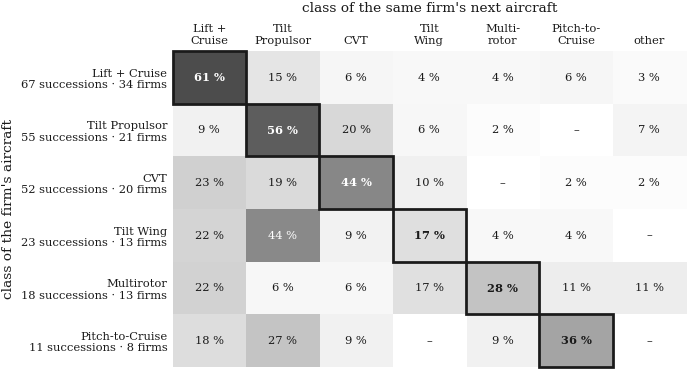

In [16]:
dest = [('SLC', 'Lift +\nCruise'), ('TR', 'Tilt\nPropulsor'), ('CVT', 'CVT'), ('TW', 'Tilt\nWing'), ('MR', 'Multi-\nrotor'), ('PTC', 'Pitch-to-\nCruise'), ('other', 'other')]
M = succ[[f"→ {c}" for c, _ in dest]].to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(W, 3.4), constrained_layout=True)
im = ax.imshow(M, cmap='Greys', vmin=0, vmax=0.8, aspect='auto')
for i, r in succ.reset_index(drop=True).iterrows():
    for j, (c, _) in enumerate(dest):
        val = M[i, j]
        ax.text(j, i, f"{100 * val:.0f} %" if val > 0 else '–', ha='center', va='center', fontsize=7.5, color='white' if val >= 0.4 else style.INK,
                fontweight='bold' if c == r['code'] else None)
        if c == r['code']:
            ax.add_patch(matplotlib.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=style.INK, linewidth=1.8, zorder=5, clip_on=False))
ax.set_xticks(range(len(dest)), [d[1] for d in dest], fontsize=7.5); ax.xaxis.tick_top()
ax.set_yticks(range(len(succ)), [f"{'CVT' if c == 'CVT' else style.cls(c).name}\n{int(n)} successions · {int(f)} firms" for c, n, f in zip(succ['code'], succ['successions'], succ['firms'])], fontsize=7.5)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_ylabel("class of the firm's aircraft")
ax.set_xlabel("class of the same firm's next aircraft"); ax.xaxis.set_label_position('top'); ax.xaxis.labelpad = 8
plt.show()
save.figure(fig, cfg, 'q4', 'fig_20_successions', data=succ,
            caption="where a firm's next aircraft lands, by the class of the one before; the boxed cell is the share that stays in the class.",
            source='PatSeer (assignee, priority date) · human labelling',
            unit=f"the succession: a named organisation's aircraft and the same firm's next aircraft in priority order ({int(succ.iloc[0]['successions, all classes'])} of them, from the {int(succ.iloc[0]['firms with a succession'])} firms with two aircraft or more); the classes of origin with {frames.CH4_SUCC_MIN} successions or more",
            read="Each row is the class of a firm's aircraft; each cell the share of the firm's next aircraft that lands in the column's class (a row sums to 100 %; – is none). Darker is a larger share. The boxed cell, in bold, is the share that stays in the class. Under each class: its successions and the firms that make them; a firm with many aircraft contributes many successions.")
plt.close(fig)

### 4.2 numbers

In [17]:
eti, twi, si = et.set_index('window'), twe.set_index('window'), succ.set_index('code')
N2 = {'c4_test_min': str(frames.CH4_TEST_MIN), 'c4_succ_min': str(frames.CH4_SUCC_MIN),
      'c4_p_1619': pval(eti.loc['2016-19', 'p']), 'c4_p_2023': pval(eti.loc['2020-23', 'p']),
      'c4_big_1619': eti.loc['2016-19', 'largest returning firm'], 'c4_big_ret_1619': str(int(eti.loc['2016-19', 'its aircraft'])),
      'c4_ret_1619': str(int(eti.loc['2016-19', 'returning aircraft'])),
      'c4_ent_1619': str(int(twi.loc['2016-19', 'firms entering'])), 'c4_ent_2023': str(int(twi.loc['2020-23', 'firms entering'])),
      'c4_tw_n_1619': str(int(twi.loc['2016-19', 'entering with Tilt Wing'])), 'c4_tw_n_2023': str(int(twi.loc['2020-23', 'entering with Tilt Wing'])),
      'c4_pairs': str(len(pairs)), 'c4_pair_firms': str(pairs['firm'].nunique()),
      'c4_slc_stay': pct(si.loc['SLC', 'stays in the class']), 'c4_tr_stay': pct(si.loc['TR', 'stays in the class']), 'c4_tw_stay': pct(si.loc['TW', 'stays in the class'])}
numbers_check(N2)

,name,notebook,document,match
0,c4_test_min,20,20,yes
1,c4_succ_min,10,10,yes
2,c4_p_1619,0.017,0.017,yes
3,c4_p_2023,0.07,0.07,yes
4,c4_big_1619,Bell / Textron,Bell / Textron,yes
5,c4_big_ret_1619,33,33,yes
6,c4_ret_1619,57,57,yes
7,c4_ent_1619,57,57,yes
8,c4_ent_2023,82,82,yes
9,c4_tw_n_1619,7,7,yes


In [18]:
# also quoted in the takeaways of 4.2 (not in the document's number list): each against the figure the document prints
e16, e20 = es[es['window'] == '2016-19'].set_index('group'), es[es['window'] == '2020-23'].set_index('group')
tw23 = twi.loc['2020-23']
EXTRA2 = {
    'first-time aircraft of named organisations 2016-19, 2020-23': (f"{int(eti.loc['2016-19', 'first-time aircraft'])} of {int(eti.loc['2016-19', 'first-time aircraft'] + eti.loc['2016-19', 'returning aircraft'])}, {int(eti.loc['2020-23', 'first-time aircraft'])} of {int(eti.loc['2020-23', 'first-time aircraft'] + eti.loc['2020-23', 'returning aircraft'])}", '98 of 155, 120 of 181'),
    '2016-19 returning: Tilt Propulsor against first-time': (f"{pct(e16.loc['returning filers', 'Tilt Rotor'])} against {pct(e16.loc['first-time filers', 'Tilt Rotor'])}", '35 % against 13 %'),
    '2016-19 first-time: Lift + Cruise against returning': (f"{pct(e16.loc['first-time filers', 'Lift + Cruise'])} against {pct(e16.loc['returning filers', 'Lift + Cruise'])}", '32 % against 14 %'),
    'chi-square p without the largest returning firm': (f"{pval(eti.loc['2016-19', 'p without it'])}, {pval(eti.loc['2020-23', 'p without it'])}", '0.59, 0.38'),
    'Tilt Wing entering share 2016-19, 2020-23': (f"{pct(twi.loc['2016-19', 'Tilt Wing share of entrants'])}, {pct(twi.loc['2020-23', 'Tilt Wing share of entrants'])}", '12 %, 11 %'),
    'Tilt Wing share of the aircraft 2016-19, 2020-23': (f"{pct(twi.loc['2016-19', 'Tilt Wing share of the aircraft'])}, {pct(twi.loc['2020-23', 'Tilt Wing share of the aircraft'])}", '11 %, 8 %'),
    'Fisher p of that fall': (f"p {tw23['Tilt Wing share, Fisher p against the window before']:.2f}", 'p 0.33'),
    'Tilt Wing entrants 2020-23: universities, no other aircraft': (f"{int(tw23['Tilt Wing entrants: universities / institutes'])} ({pct(tw23['Tilt Wing entrants: universities / institutes'] / tw23['entering with Tilt Wing'])}), {int(tw23['Tilt Wing entrants: no other aircraft'])} ({pct(tw23['Tilt Wing entrants: no other aircraft'] / tw23['entering with Tilt Wing'])})", '3 (33 %), 6 (67 %)'),
    'all entrants 2020-23: universities, no other aircraft': (f"{int(tw23['all entrants: universities / institutes'])} ({pct(tw23['all entrants: universities / institutes'] / tw23['firms entering'])}), {int(tw23['all entrants: no other aircraft'])} ({pct(tw23['all entrants: no other aircraft'] / tw23['firms entering'])})", '15 (18 %), 56 (68 %)'),
    'CVT stays': (pct(si.loc['CVT', 'stays in the class']), '44 %'),
    'Tilt Wing successions and firms': (f"{int(si.loc['TW', 'successions'])}, {int(si.loc['TW', 'firms'])}", '23, 13'),
    'Tilt Wing goes to Tilt Propulsor, Lift + Cruise': (f"{pct(si.loc['TW', '→ TR'])}, {pct(si.loc['TW', '→ SLC'])}", '44 %, 22 %'),
    'successions of the largest filer': (f"{succ.iloc[0]['firm left out']}, {int(succ.iloc[0]['its successions, all classes'])} of {int(succ.iloc[0]['successions, all classes'])}", 'Bell / Textron, 59 of 240'),
}
extra2 = pd.DataFrame([{'quoted': k, 'notebook': m, 'document': d, 'match': 'yes' if checks._norm(m) == checks._norm(d) else 'NO'} for k, (m, d) in EXTRA2.items()])
extra2

,quoted,notebook,document,match
0,"first-time aircraft of named organisations 2016-19, 2020-23","98 of 155, 120 of 181","98 of 155, 120 of 181",yes
1,2016-19 returning: Tilt Propulsor against first-time,35 % against 13 %,35 % against 13 %,yes
2,2016-19 first-time: Lift + Cruise against returning,32 % against 14 %,32 % against 14 %,yes
3,chi-square p without the largest returning firm,"0.59, 0.38","0.59, 0.38",yes
4,"Tilt Wing entering share 2016-19, 2020-23","12 %, 11 %","12 %, 11 %",yes
5,"Tilt Wing share of the aircraft 2016-19, 2020-23","11 %, 8 %","11 %, 8 %",yes
6,Fisher p of that fall,p 0.33,p 0.33,yes
7,"Tilt Wing entrants 2020-23: universities, no other aircraft","3 (33 %), 6 (67 %)","3 (33 %), 6 (67 %)",yes
8,"all entrants 2020-23: universities, no other aircraft","15 (18 %), 56 (68 %)","15 (18 %), 56 (68 %)",yes
9,CVT stays,44 %,44 %,yes


## Overview: what matched

Every number the document quotes for chapter 4 (56) and every table, with the differences labelled.

In [19]:
allnum = pd.concat(NUMBERS, ignore_index=True)
n_doc = len(checks.reference_numbers('4'))
missing = checks.missing_numbers(dict.fromkeys(allnum['name']), '4')
print(f"numbers: {int((allnum['match'] == 'yes').sum())} of {len(allnum)} match the document; "
      f"{int(allnum['match'].str.startswith('expected').sum())} expected differences; {int((allnum['match'] == 'NO').sum())} failures; "
      f"{len(missing)} of the document's {n_doc} not computed here: {missing}")
overview = pd.DataFrame([c.iloc[0].to_dict() for c in CHECKS])
overview

numbers: 56 of 56 match the document; 0 expected differences; 0 failures; 0 of the document's 56 not computed here: []


,table,rows (notebook | document),cells compared,matched,expected differences,differences,status
0,la_filer_mix,4 | 4,24,24,0,0,match
1,la_filer_mix_rep,4 | 4,8,8,0,0,match
2,la_coverage_segments,4 | 4,20,20,0,0,match
3,la_filers_by_window,5 | 5,40,40,0,0,match
4,la_class_concentration_brief,7 | 7,91,91,0,0,match
5,la_firm_leverage,31 | 31,279,279,0,0,match
6,la_firm_leverage_classes,96 | 96,1056,1056,0,0,match
7,la_ari_funding,18 | 18,162,162,0,0,match
8,la_ari_funding_tests,3 | 3,12,12,0,0,match
9,la_entry_split,8 | 8,64,64,0,0,match


In [20]:
assert (allnum['match'] != 'NO').all(), allnum[allnum['match'] == 'NO']
assert not missing
assert (overview['differences'] == 0).all(), overview[overview['differences'] > 0]
assert (extra1['match'] == 'yes').all(), extra1[extra1['match'] == 'NO']
assert (extra2['match'] == 'yes').all(), extra2[extra2['match'] == 'NO']